# Assignment 1 — Making Sense of Northgate through Visualization
**INFO 4670 · Data Analysis and Knowledge Discovery**  ·  **Due: Sunday, 11:59 PM**

**Name:** Arya Kumar    **Date:** 09/03/2026

**The situation.** The Provost's question stands: *which students are struggling, and can we see it earlier?* This week you answer it the way analysts do — not by reading rows, but by drawing the data. Every chart below is built by **adapting code from the Guided notebook**; the intellectual work is choosing the right chart and reading it honestly.

**For every chart you make, you must:**
1. **Choose** the chart type that fits the variable(s) and the question.
2. **Build** it in Colab from the Northgate files.
3. **Label** it fully — title, axis labels, and units/legend. *An unlabeled chart is an unfinished chart.*
4. **Write a STAR story** underneath it — Scope · Track · Articulate · Respond (defined on the Concepts deck).

**How to work:** run Setup and Load first. Then, for each question, copy the closest cell from the Guided notebook into the empty cell, adapt it, and fill in the STAR cell below it.

**Submit:** push this notebook to GitHub and submit the **GitHub link** in Canvas. (See the setup doc: *Colab_GitHub_Setup_INFO4670_Fall2026*.)

## Setup — run this first (you don't need to change it)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

## Load the data — run this, then look before you plot

In [2]:
# STEP 1 — get the data into this notebook. Pick ONE option, then run.

DATA_DIR = "."   # OPTION 2 (default) · drag the 3 CSVs into the file panel on the left

# OPTION 1 · read from Google Drive — uncomment and edit the path:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/.../Data"

import os
students = pd.read_csv(os.path.join(DATA_DIR, "student_records.csv"))
weekly   = pd.read_csv(os.path.join(DATA_DIR, "weekly_activity.csv"))
students.head()

,student_id,major,age,housing,commute_miles,work_hours_per_week,advisor_meetings,credits_attempted,final_gpa,study_hours_reported,enrollment_date,dropped_out
0,NU-101508,Data Science,27,Off-Campus,7.6,15,1,81,1.86,NaN,2023-09-13,1
1,NU-102438,Learning Technologies,25,With Family,14.3,35,1,100,2.06,9.5,2023-10-19,0
2,NU-102385,Learning Technologies,26,With Family,3.4,18,9,77,3.41,19.1,11/16/2022,0
3,NU-100767,Cyber Security,22,On-Campus,23.7,40,1,65,1.73,8.1,2024-05-03,0
4,NU-106054,Information Technology,21,Off-Campus,2.3,20,4,59,2.37,6.6,10/24/2022,0


In [3]:
# how many rows, which columns, what types?
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 2027 entries, 0 to 2026
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            2027 non-null   str    
 1   major                 2027 non-null   str    
 2   age                   2027 non-null   int64  
 3   housing               2027 non-null   str    
 4   commute_miles         2027 non-null   float64
 5   work_hours_per_week   2027 non-null   int64  
 6   advisor_meetings      2027 non-null   int64  
 7   credits_attempted     2027 non-null   int64  
 8   final_gpa             2027 non-null   float64
 9   study_hours_reported  1772 non-null   float64
 10  enrollment_date       2027 non-null   str    
 11  dropped_out           2027 non-null   int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 190.2 KB


# Part A — Guided questions
Build **one chart per question**. Each maps to one chart family from this week. Copy the closest Guided-notebook cell, adapt it, label it, then write its STAR story.

### Q1 · One quantitative variable
**How many hours per week do Northgate students work?** Describe what's typical, how spread out it is, and whether anyone stands apart.
→ *histogram* (add a *box plot* if it helps). Column: `work_hours_per_week` (from `students`).

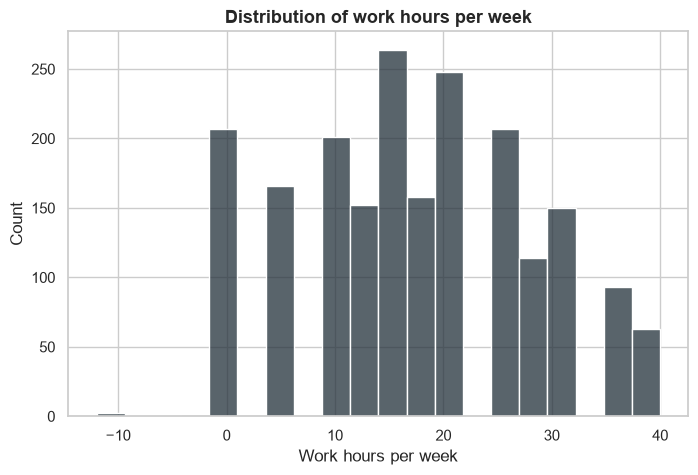

In [4]:
# Q1: Histogram of work hours per week
fig, ax = plt.subplots()
sns.histplot(data=students, x="work_hours_per_week", bins=20, color=NAVY, ax=ax)
ax.set_title("Distribution of work hours per week")
ax.set_xlabel("Work hours per week")
ax.set_ylabel("Count")
plt.show()


**STAR story — Q1**

- **Scope —** Column: `work_hours_per_week` for all students in `students` (n=2027).
- **Track —** How many hours per week do students typically work?
- **Articulate —** Typical students work about 18 hours/week (median=18, mean≈17.3). The middle 50% work roughly 10–25 hours/week (25th=10, 75th=25). Distribution is spread (std≈10.4) with a maximum of 40 hours.
- **Respond —** There is at least one invalid-looking value (min = -12). I would check data entry or coding (negative hours) and trim/clean outliers before any modelling.

### Q2 · One categorical variable
**How does enrollment compare across majors?**
→ *sorted bar chart*. Column: `major` (from `students`).

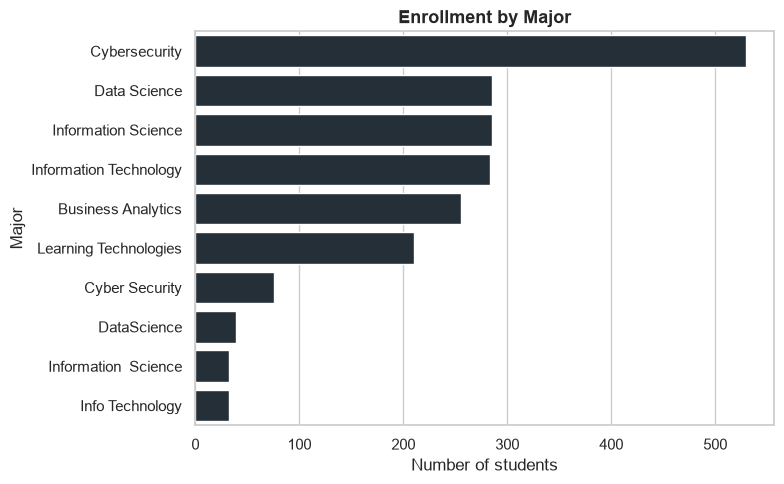

In [5]:
# Q2: Sorted bar chart of enrollment by major
major_counts = students['major'].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots()
sns.barplot(x=major_counts.values, y=major_counts.index, color=NAVY, ax=ax)
ax.set_title("Enrollment by Major")
ax.set_xlabel("Number of students")
ax.set_ylabel("Major")
plt.tight_layout()
plt.show()


**STAR story — Q2**

- **Scope —** Column: `major` for all students in `students` (n=2027).
- **Track —** How does enrollment compare across majors?
- **Articulate —** `Cybersecurity` is the largest single label (530 students). Several majors have 200–300 students (e.g., `Information Science`, `Data Science`, `Information Technology`). There are smaller variants like `DataScience`, `Info Technology`, and `Information  Science` which split counts across similar majors.
- **Respond —** The major names are inconsistent (spacing/casing/duplicates). I would standardize/merge equivalent labels before reporting exact enrollment comparisons.

### Q3 · A quantity, split by category
**Does final GPA differ across majors?** Read the exceptions, not just the boxes.
→ *box plot per major*. Columns: `final_gpa` and `major` (from `students`).

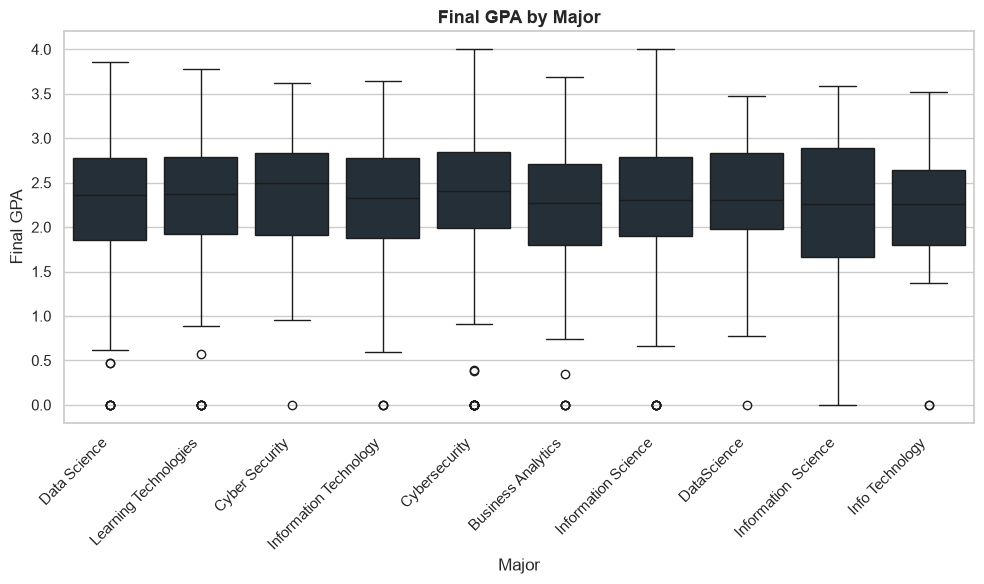

In [6]:
# Q3: Box plot of final GPA by major
fig, ax = plt.subplots(figsize=(10,6))
sns.boxplot(data=students, x="major", y="final_gpa", color=NAVY, ax=ax)
ax.set_title("Final GPA by Major")
ax.set_xlabel("Major")
ax.set_ylabel("Final GPA")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**STAR story — Q3**

- **Scope —** Columns: `final_gpa` by `major` for students in `students`.
- **Track —** Does final GPA differ across majors?
- **Articulate —** Median GPAs cluster around ~2.25–2.5 across majors (e.g., Cybersecurity median≈2.41, Business Analytics median≈2.27). Standard deviations are similar across groups, and maximums reach ≈3.5–4.0 for larger majors. Many majors show similar central tendency and spread.
- **Respond —** There are zeros in `final_gpa` (min=0.0) which may indicate missing or placeholder values—verify and clean these before comparing performance rigorously.

### Q4 · Two quantitative variables
**Is there a relationship between how far students commute and their final GPA?** Remember: *association is not causation.*
→ *scatterplot with a trend line*. Columns: `commute_miles` and `final_gpa` (from `students`).

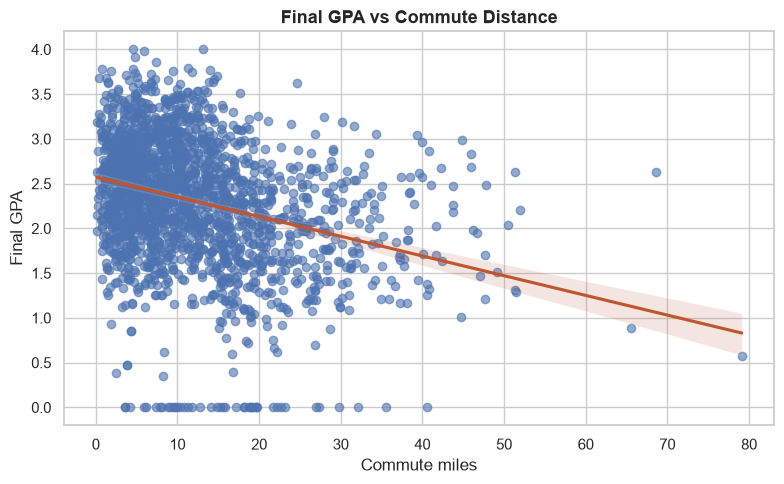

In [7]:
# Q4: Scatterplot of commute miles vs final GPA with trend line
fig, ax = plt.subplots()
sns.regplot(data=students, x="commute_miles", y="final_gpa", scatter_kws={'alpha':0.6}, line_kws={'color':RUST}, ax=ax)
ax.set_title("Final GPA vs Commute Distance")
ax.set_xlabel("Commute miles")
ax.set_ylabel("Final GPA")
plt.tight_layout()
plt.show()


**STAR story — Q4**

- **Scope —** Columns: `commute_miles` and `final_gpa` for students in `students`.
- **Track —** Is there a relationship between commute distance and final GPA?
- **Articulate —** The variables show a weak-to-moderate negative association (Pearson r ≈ -0.30): students with longer commutes tend to have slightly lower GPAs on average. The scatter shows spread at all commute lengths but a downward trend line.
- **Respond —** Association is not causation—investigate confounders (hours worked, course load, socioeconomic factors) and whether commute is correlated with other risk factors.

### Q5 · Over time
**How does student engagement change across the semester?**
→ *line chart* of average weekly activity. Use the `weekly` table: `week` and `minutes_active` (you'll need to average by week first — see the Guided notebook).

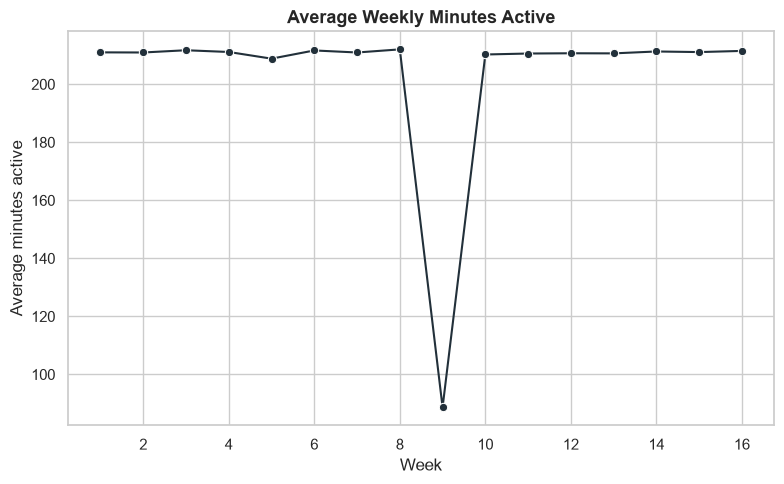

In [8]:
# Q5: Line chart of average weekly minutes active
weekly_avg = weekly.groupby('week', as_index=False)['minutes_active'].mean()
fig, ax = plt.subplots()
sns.lineplot(data=weekly_avg, x='week', y='minutes_active', marker='o', color=NAVY, ax=ax)
ax.set_title("Average Weekly Minutes Active")
ax.set_xlabel("Week")
ax.set_ylabel("Average minutes active")
plt.tight_layout()
plt.show()


**STAR story — Q5**

- **Scope —** Weekly averages of `minutes_active` from the `weekly` table (averaged across students per week).
- **Track —** How does student engagement change across the semester?
- **Articulate —** Average weekly minutes active are roughly stable at ≈210 minutes/week for most weeks. Week 9 is a clear anomaly with a much lower average (~88.6 minutes).
- **Respond —** Investigate week 9 (data collection issue, holiday, or encoding error). Also check for missing participants or mis-recorded week values.

# Part B — Your own question (open)
Pose **one question of your own** about the Northgate students, choose the chart that answers it, build it, label it, and write its STAR story. Going beyond Part A is rewarded — a per-student line chart, a violin plot, or a chart of a messier column are all fair game.

**Your question:** \_\_\_\_\_\_\_\_



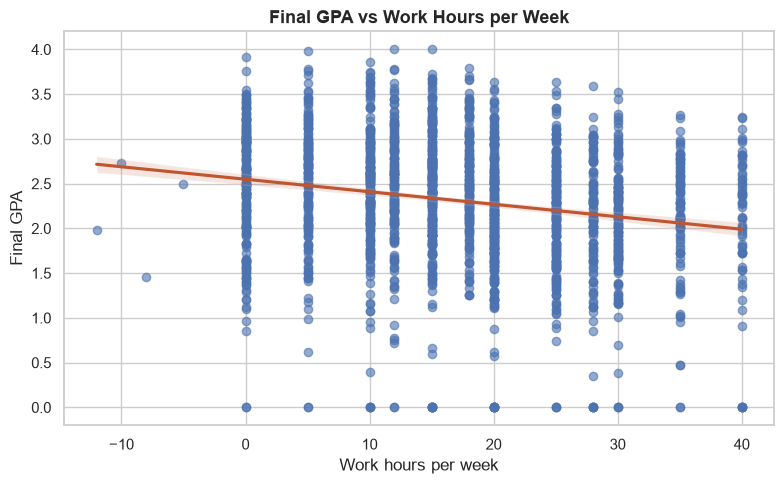

In [9]:
# Part B: Does work hours relate to final GPA?
fig, ax = plt.subplots()
sns.regplot(data=students, x='work_hours_per_week', y='final_gpa', scatter_kws={'alpha':0.6}, line_kws={'color':RUST}, ax=ax)
ax.set_title("Final GPA vs Work Hours per Week")
ax.set_xlabel("Work hours per week")
ax.set_ylabel("Final GPA")
plt.tight_layout()
plt.show()


**STAR story — Part B**

- **Scope —** Columns: `work_hours_per_week` and `final_gpa` for students in `students` (shown with a regression line).
- **Track —** Is there a relationship between how many hours students work and their final GPA?
- **Articulate —** There is a weak negative association (Pearson r ≈ -0.21): students who work more hours tend to have slightly lower GPAs on average. Typical work hours are around 18/week; the relationship is noisy with many students at all GPA levels.
- **Respond —** This is associative only. Consider checking nonlinear effects, splitting by full-/part-time, controlling for major and course load, and verifying there are no coding issues (e.g., zeros or negatives in hours).

# Before you submit — checklist
- [ ] The notebook **runs top to bottom** with no errors (Runtime → Restart and run all).
- [ ] All **6 charts** are present, each with a title, labeled axes, and units/legend where needed.
- [ ] Each chart has a **complete STAR story**, including any exceptions you spotted.
- [ ] Part B question is written in and answered.
- [ ] Pushed to **GitHub**, and the **GitHub link** is submitted in Canvas.

**Rubric (70 pts):** chart choice 10 · correct build 20 · labeling 10 · STAR reading 18 · Part B question 4 · submission & professionalism 8.